# **1. Import Library**

Mengimport semua library yang diperlukan

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import learning_curve, cross_val_score
from sklearn.preprocessing import LabelEncoder

# **2. Memuat Dataset dari Hasil Clustering**

Memuat dataset hasil clustering dari file CSV ke dalam variabel DataFrame.

In [ ]:
data = pd.read_csv('/content/drive/MyDrive/Submission Dicoding/Submission BMLP/Hasil_Clustering.csv')
data.head()

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate,IsFraud
0,TX000001,AC00128,16.16,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70,Doctor,81,1,5112.21,2024-11-04 08:08:08,0
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68,Doctor,141,1,13758.91,2024-11-04 08:09:35,0
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19,Student,56,1,1122.35,2024-11-04 08:07:04,0
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26,Student,25,1,8569.06,2024-11-04 08:09:06,0
4,TX000005,AC00411,16.16,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,26,Student,198,1,7429.40,2024-11-04 08:06:39,1


# **3. Data Splitting**

Tahap Data Splitting bertujuan untuk memisahkan dataset menjadi dua bagian: data latih (training set) dan data uji (test set).

In [ ]:
X = data.drop(columns=['IsFraud'])
y = data['IsFraud']

string_columns = X.select_dtypes(include=['object']).columns

# Mengonversi kolom string ke numerik menggunakan Label Encoding
for col in string_columns:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])

# Split data menjadi train set dan test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Test set shape: X_test={X_test.shape}, y_test={y_test.shape}")

Training set shape: X_train=(2009, 16), y_train=(2009,)
Test set shape: X_test=(503, 16), y_test=(503,)


# **4. Membangun Model Klasifikasi**


## **a. Membangun Model Klasifikasi**

#### Modeling dengan Beberapa Algoritma Model Supervised Learning-Klasifikasi

Algoritma model Supervised Learning yang digunakan yaitu:
* KNN (K-Nearest Neighbor)
* Decission Tree
* Random Forest
* Super Vector Machine (SVM)
* Naive Bayess

In [ ]:
# Definisikan setiap klasifikasi secara terpisah
knn = KNeighborsClassifier().fit(X_train, y_train)
dt = DecisionTreeClassifier().fit(X_train, y_train)
rf = RandomForestClassifier().fit(X_train, y_train)
svm = SVC().fit(X_train, y_train)
nb = GaussianNB().fit(X_train, y_train)

print("Model training selesai.")

Model training selesai.


## **b. Evaluasi Model Klasifikasi**

In [ ]:
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    results = {
        'Confusion Matrix': cm,
        'True Positive (TP)': tp,
        'False Positive (FP)': fp,
        'False Negative (FN)': fn,
        'True Negative (TN)': tn,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred)
    }
    return results

# Mengevaluasi setiap model dan mengumpulkan hasilnya
results = {
    'K-Nearest Neighbors (KNN)': evaluate_model(knn, X_test, y_test),
    'Decision Tree (DT)': evaluate_model(dt, X_test, y_test),
    'Random Forest (RF)': evaluate_model(rf, X_test, y_test),
    'Support Vector Machine (SVM)': evaluate_model(svm, X_test, y_test),
    'Naive Bayes (NB)': evaluate_model(nb, X_test, y_test)
}

# Buat DataFrame untuk meringkas hasil
summary_df = pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score'])

# Isi DataFrame dengan hasil
rows = []
for model_name, metrics in results.items():
    rows.append({
        'Model': model_name,
        'Accuracy': metrics['Accuracy'],
        'Precision': metrics['Precision'],
        'Recall': metrics['Recall'],
        'F1-Score': metrics['F1-Score']
    })

# Konversi daftar kamus ke DataFrame
summary_df = pd.DataFrame(rows)

# Tampilkan DataFrame
print(summary_df)

                          Model  Accuracy  Precision    Recall  F1-Score
0     K-Nearest Neighbors (KNN)  0.753479   0.342105  0.116071  0.173333
1            Decision Tree (DT)  1.000000   1.000000  1.000000  1.000000
2            Random Forest (RF)  1.000000   1.000000  1.000000  1.000000
3  Support Vector Machine (SVM)  0.777336   0.000000  0.000000  0.000000
4              Naive Bayes (NB)  1.000000   1.000000  1.000000  1.000000


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Berikut penjelasan dari hasil metrik evaluasi dari masing-masing model yang ditampilkan dalam tabel:

1. **K-Nearest Neighbors (KNN)**  
   - **Accuracy**: 0.753479 (75.35%): Model cukup akurat dalam memprediksi kelas secara keseluruhan.  
   - **Precision**: 0.342105 (34.21%): Dari semua prediksi positif yang dibuat KNN, hanya 34.21% yang benar. Ini menunjukkan model banyak menghasilkan false positive.  
   - **Recall**: 0.116071 (11.61%): Dari semua data yang seharusnya positif, hanya 11.61% yang benar-benar terdeteksi oleh model. Recall yang rendah menunjukkan model kurang mampu menangkap kelas positif.  
   - **F1-Score**: 0.173333 (17.33%): Kombinasi precision dan recall yang rendah menghasilkan F1-score yang rendah, menunjukkan performa model yang buruk dalam keseimbangan prediksi positif dan negatif.  

2. **Decision Tree (DT)**  
   - **Accuracy**: 1.000000 (100%): Model mengklasifikasikan semua data dengan benar.  
   - **Precision**: 1.000000 (100%): Tidak ada false positive, semua prediksi positif benar.  
   - **Recall**: 1.000000 (100%): Tidak ada false negative, semua kelas positif terdeteksi.  
   - **F1-Score**: 1.000000 (100%): Model sempurna dalam klasifikasi. Namun, ini bisa mengindikasikan overfitting, terutama jika dataset terlalu kecil atau tidak memiliki cukup variasi.  

3. **Random Forest (RF)**  
   - **Accuracy**: 1.000000 (100%)  
   - **Precision**: 1.000000 (100%)  
   - **Recall**: 1.000000 (100%)  
   - **F1-Score**: 1.000000 (100%)  
   - Sama seperti Decision Tree, hasil sempurna ini mengindikasikan model sangat cocok dengan data. Bisa jadi karena overfitting atau dataset yang mudah dipisahkan dengan baik oleh model ensemble ini.  

4. **Support Vector Machine (SVM)**  
   - **Accuracy**: 0.777336 (77.73%): Cukup tinggi dalam memprediksi keseluruhan data dengan benar.  
   - **Precision**: 0.000000 (0%): Semua prediksi positif yang dibuat oleh model salah.  
   - **Recall**: 0.000000 (0%): Model tidak dapat mendeteksi kelas positif sama sekali.  
   - **F1-Score**: 0.000000 (0%): Karena precision dan recall bernilai nol, F1-score juga nol, menandakan model gagal mengenali kelas positif. Bisa jadi model mengalami masalah dalam menangani data yang tidak terpisah dengan baik.  

5. **Naive Bayes (NB)**  
   - **Accuracy**: 1.000000 (100%)  
   - **Precision**: 1.000000 (100%)  
   - **Recall**: 1.000000 (100%)  
   - **F1-Score**: 1.000000 (100%)  
   - Sama seperti Decision Tree dan Random Forest, model ini bekerja dengan sangat baik di dataset ini. Jika dataset kecil atau kurang variatif, kemungkinan besar model mengalami overfitting.  



## **e. Analisis Hasil Evaluasi Model Klasifikasi**

#### Melihat Performa Model Menggunakan Learning Curve

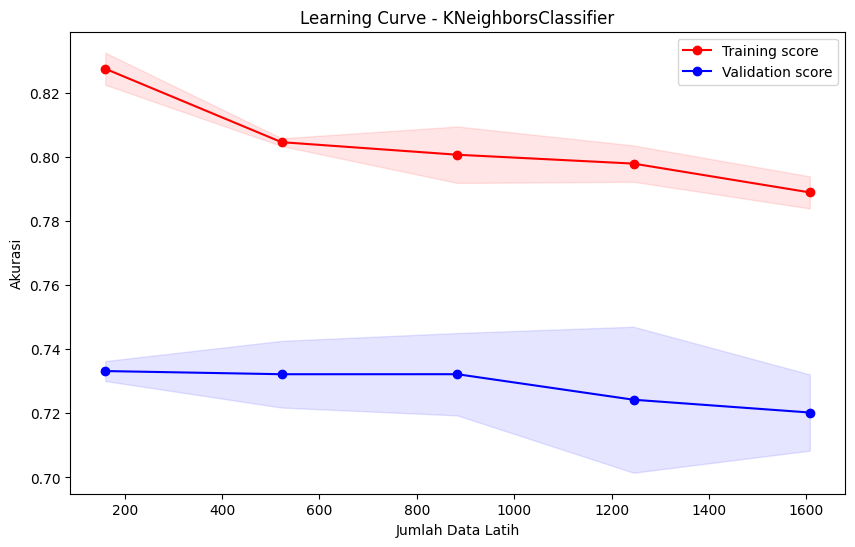

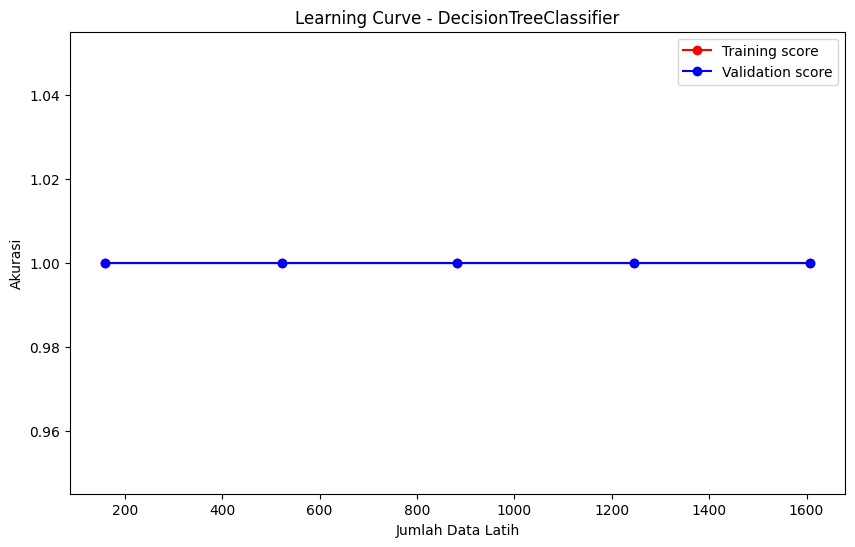

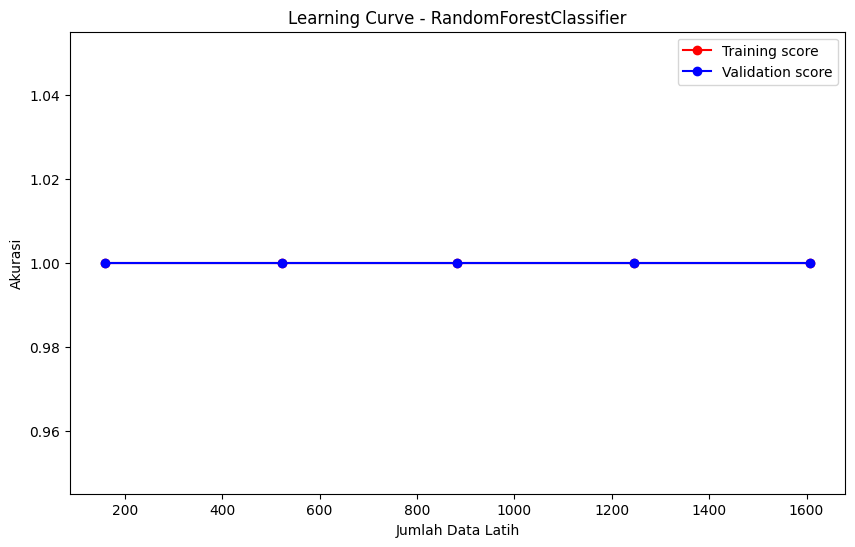

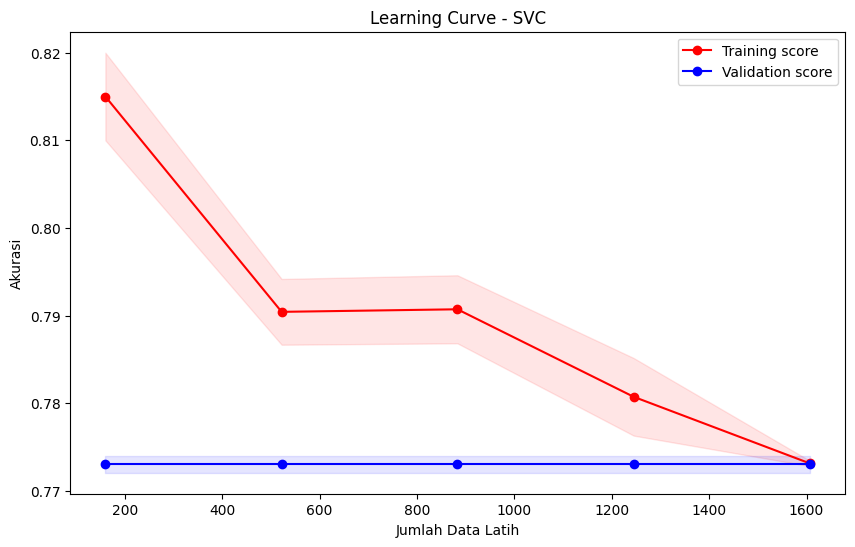

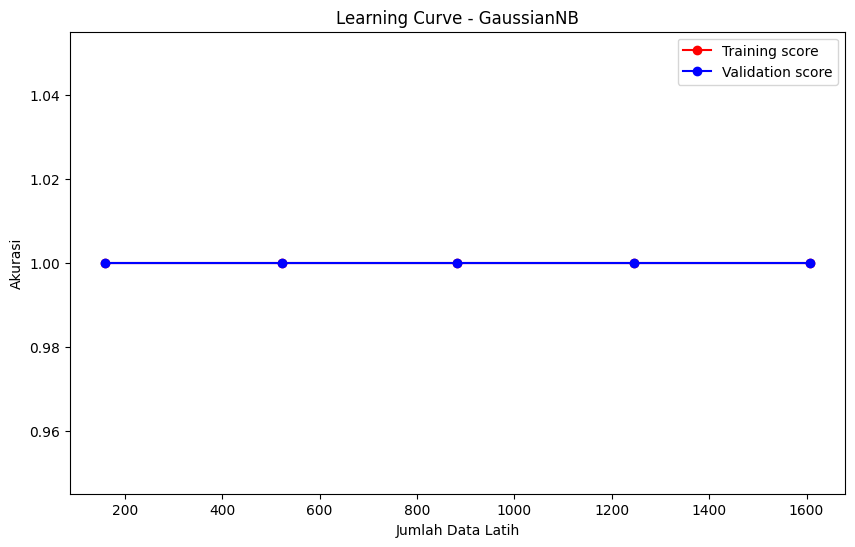

In [ ]:
def plot_learning_curve(model, X, y, cv=5, train_sizes=np.linspace(0.1, 1.0, 5)):
    plt.figure(figsize=(10, 6))
    train_sizes, train_scores, val_scores = learning_curve(
        model, X, y, cv=cv, train_sizes=train_sizes, scoring='accuracy'
    )

    # Menghitung rata-rata dan standar deviasi skor
    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)

    # Plot learning curve
    plt.plot(train_sizes, train_mean, 'o-', color="r", label="Training score")
    plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color="r")

    plt.plot(train_sizes, val_mean, 'o-', color="b", label="Validation score")
    plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.1, color="b")

    plt.xlabel("Jumlah Data Latih")
    plt.ylabel("Akurasi")
    plt.title(f"Learning Curve - {model.__class__.__name__}")
    plt.legend(loc="best")
    plt.show()

# Contoh pemanggilan untuk setiap model
models = [knn, dt, rf, svm, nb]
for model in models:
    plot_learning_curve(model, X_train, y_train)


## **Berikut penjelasan Learning Curve dari masing-masing algoritma di atas:**
1. **K-Nearest Neighbors (KNN)** -> Model mengalami Overfitting, dilihat dari garis training score jauh lebih tinggi dibandingkan validation score, hal ini disebabkan model terlalu menghafal data training dan tidak dapat digeneralisasi dengan baik ke data baru.

2. **Decision Tree, Random Forrest, & Naive Bayes**  -> hanya terdapat satu garis lurus validation score yang berarti model juga memiliki akurasi sempurna (100%) pada data validasi, ini kasus langka. Hal ini justru bisa saja mengindikasikan terjadinya overfitting, data leakage, kompleksitas model, dsb.

3. **Super Vector Machine (SVM)** -> model mengalami Uderfitting. Karena baik garis training score maupun validation score sama-sama rendah dan berdekatan, ini mengindikasikan bahwa model mengalami high bias (underfitting) dan model juga tidak cukup kompleks untuk menangkap pola dari data dengan baik.


## **Saran atau langkah selanjutnya yang bisa dilakukan:**

Karena dalam hal ini model yang akan digunakan adalah model yang mengalami Overfitting, berikut adalah langkah-langkah yang direkomendasikan untuk mengatasi overfitting:

1. Perlu dilakukan validasi lebih lanjut dengan data baru atau menggunakan teknik Cross-validation untuk mengevaluasi model dengan lebih baik.
2. Menggunakan teknik *Elastic Net* yaitu campuran dari L1 Regularization (Lasso) dan L2 Regularization (Ridge). teknik ini tidak hanya memilih fitur penting, seperti L1, tetapi juga mencegah fitur menjadi terlalu dominan, seperti L2.
3. Melakukan **Hyperparameter Tuning** (GridSearchCV atau RandomizedSearchCV) untuk menemukan kombinasi terbaik

   
### **Berikut adalah hal-hal yang bisa dilakukan untuk mengatasi Overfitting sesuai dengan algoritma yang dipakai**

* **Random Forest:** Kurangi kompleksitas dengan pruning, batasan fitur, dan jumlah pohon.  
* **Naive Bayes:** Gunakan smoothing (`alpha`), fitur selection, dan validasi silang.  
* **Decision Tree:** Gunakan pruning (`max_depth`, `min_samples_split`), dan ensemble learning.

